# 02 - Train the proxy model
**What this notebook does:** teaches a fast model (the *proxy*) to predict the production curves from the 4 parameters. It compares 3 methods, picks the best on the validation cases, gives an honest final score on the test cases, and saves the model for notebook 03.

**How it works, in plain words:**
1. Each curve has 41 numbers (one per quarter). **PCA** squeezes it into ~3-6 numbers that still describe its shape.
2. A regression method learns *4 parameters -> those few numbers*.
3. To predict, we go backwards: parameters -> few numbers -> full curve.

The 3 methods compared: **Gaussian Process** (great with little, smooth data), **polynomial** (a simple curve-fit baseline), **random forest** (a popular general-purpose method).

**How to run:** Runtime -> Run all (about 5 minutes). Needs notebook 01.

In [1]:
# SETUP - run this cell first, every time you open the notebook.
# It connects Google Drive, installs one extra package and loads our helper code.
import os, sys, subprocess, importlib
try:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE = '/content/drive/MyDrive/DWC26'          # the shared team folder
except ImportError:                                 # (only used when running outside Colab)
    BASE = os.environ.get('DWC_BASE', 'DWC26')
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'python-calamine'], check=False, capture_output=True)
sys.path.insert(0, f'{BASE}/notebooks')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import dwc_utils as du; importlib.reload(du)
P = du.get_paths(BASE)
pd.set_option('display.float_format', lambda x: f'{x:,.4g}')
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})
print('Ready. Project folder:', BASE)

Mounted at /content/drive
Ready. Project folder: /content/drive/MyDrive/DWC26


In [2]:
du.require(f"{P['PROC']}/arrays.npz", 'notebook 01')
A = np.load(f"{P['PROC']}/arrays.npz")
grid = pd.to_datetime(A['grid']); gx = du.day_number(grid)
params = pd.read_parquet(f"{P['PROC']}/params.parquet").set_index('case_id').loc[A['case_ids']].reset_index()
Y = {v: A[v] for v in du.CUMS}
Xs, lo, hi = du.scale_inputs(params[du.PARAMS].values)
split = params['split'].values
tr, va, te = split == 'train', split == 'validation', split == 'test'
print(f'train {tr.sum()} / validation {va.sum()} / test {te.sum()} cases')

train 70 / validation 15 / test 15 cases


## Step 1 - Train on the 70 training cases, compare on the 15 validation cases
How to read the scores:
- **MAPE_end_%**: average % error of the predicted total at the end of 2008. Under 1% is very good.
- **R2**: 1.0 = perfect.
- **RMSE**: typical error size in barrels (oil, water) or MSCF (gas).

In [3]:
METHODS = {'gp': 'Gaussian Process', 'poly': 'Polynomial', 'forest': 'Random forest'}
rows, models = [], {}
for m in METHODS:
    for v in du.CUMS:
        model = du.PCAProxy(m).fit(Xs[tr], Y[v][tr]); models[(m, v)] = model
        rmse, mape, r2 = du.score(Y[v][va], model.predict(Xs[va]))
        rows.append({'method': METHODS[m], 'variable': v, 'set': 'validation', 'RMSE': rmse, 'MAPE_end_%': mape, 'R2': r2})
val = pd.DataFrame(rows)
display(val.pivot(index='method', columns='variable', values='MAPE_end_%').round(3))
best = val.groupby('method')['MAPE_end_%'].mean().idxmin()
BEST = [k for k, n in METHODS.items() if n == best][0]
print(f'Best on validation: {best}')

variable,gas_cum,oil_cum,water_cum
method,,,
Gaussian Process,0.036,0.038,0.104
Polynomial,0.117,0.121,0.315
Random forest,0.737,0.742,1.047


Best on validation: Gaussian Process


## Step 2 - Final honest score on the 15 test cases
The test cases were never used for training or for choosing the method, so this is the score to report in the slides and README.

In [4]:
rows = []
for m in METHODS:
    for v in du.CUMS:
        rmse, mape, r2 = du.score(Y[v][te], models[(m, v)].predict(Xs[te]))
        rows.append({'method': METHODS[m], 'variable': v, 'set': 'test', 'RMSE': rmse, 'MAPE_end_%': mape, 'R2': r2})
metrics = pd.concat([val, pd.DataFrame(rows)], ignore_index=True)
metrics.to_csv(f"{P['OUT']}/proxy_metrics.csv", index=False)
metrics.to_csv(f"{P['PBI']}/proxy_metrics.csv", index=False)
display(metrics[metrics.set == 'test'].pivot(index='method', columns='variable', values=['MAPE_end_%', 'R2']).round(4))

MAPE_end_%                        R2                  
variable            gas_cum oil_cum water_cum gas_cum oil_cum water_cum
method                                                                 
Gaussian Process     0.0538  0.0542    0.1016  0.9998  0.9997    0.9998
Polynomial           0.1324  0.1362    0.3062  0.9994  0.9994    0.9989
Random forest        0.9363  0.9333     1.581  0.9794  0.9796    0.9875

## Chart - test cases: true curve vs proxy prediction
Solid line = simulator (truth). Dashed line = proxy prediction. If they overlap, the proxy is good. This is the most convincing chart for the judges.

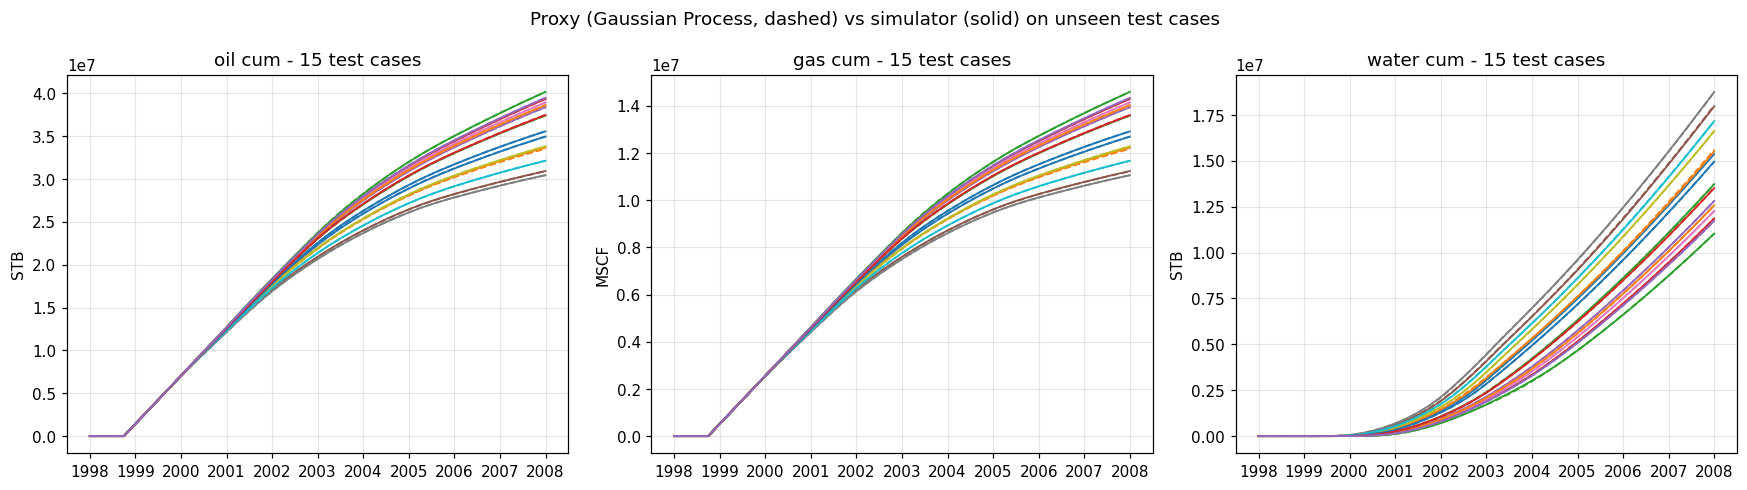

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
for a, v in zip(ax, du.CUMS):
    pred = models[(BEST, v)].predict(Xs[te])
    for i, k in enumerate(np.where(te)[0]):
        line, = a.plot(grid, Y[v][k], lw=1.2)
        a.plot(grid, pred[i], '--', color=line.get_color(), lw=1.2)
    a.set_title(f"{v.replace('_', ' ')} - 15 test cases"); a.set_ylabel(du.UNITS[v])
fig.suptitle(f'Proxy ({METHODS[BEST]}, dashed) vs simulator (solid) on unseen test cases'); fig.tight_layout()
fig.savefig(f"{P['FIG']}/06_proxy_test_cases.png", bbox_inches='tight'); plt.show()

## Step 3 - Retrain the chosen method on all 100 cases and save it
More examples make a better model, especially near the answer we will search for. We say this openly in the README: *"after selecting the method on validation and reporting test accuracy, the final proxy was retrained on all 100 cases."*

In [6]:
import joblib
final = {v: du.PCAProxy(BEST).fit(Xs, Y[v]) for v in du.CUMS}
joblib.dump({'proxy': final, 'lo': lo, 'hi': hi, 'method': BEST}, f"{P['PROC']}/proxy.joblib")
print('Saved processed/proxy.joblib using', METHODS[BEST])
for v in du.CUMS:
    print(f'  {v}: curve squeezed into {final[v].pca.n_components_} numbers')

Saved processed/proxy.joblib using Gaussian Process
  oil_cum: curve squeezed into 3 numbers
  gas_cum: curve squeezed into 3 numbers
  water_cum: curve squeezed into 3 numbers


## Insight - which parameter does the model find most important?
For the Gaussian Process, every parameter gets a **length-scale**: how far you must move that parameter before the curve changes noticeably. Short = very important; very long = barely matters.

In [7]:
if BEST == 'gp':
    for v in ['oil_cum', 'water_cum']:
        ls = final[v].models[0].kernel_.k1.k2.length_scale
        order = np.argsort(ls)
        print(f'{v}: most to least important ->', ', '.join(f"{du.PARAM_LABELS[du.PARAMS[i]]} ({ls[i]:.2f})" for i in order))
else:
    print('Length-scales are only available for the Gaussian Process.')

oil_cum: most to least important -> Porosity Multiplier (2.56), Permeability Multiplier (3.34), Aquifer Pore Volume (6.68), Fault Transmissibility (100.00)
water_cum: most to least important -> Porosity Multiplier (2.93), Permeability Multiplier (4.39), Aquifer Pore Volume (5.43), Fault Transmissibility (100.00)


**Next: notebook 03.**